# Linear Regression & Evaluation Metrics

**Regression Lab** · College of Computer Studies, University of Technology Bahrain
Prepared by **Eng. Saeed Serwan Abdulsattar**

This notebook accompanies the interactive site: **https://saeedserwan.github.io/regression/**

By the end you will be able to:

1. Fit a simple linear regression with ordinary least squares (OLS), from scratch.
2. Compute **MAE, MSE, RMSE, R², adjusted R² and MAPE** from their definitions.
3. Verify your results against scikit-learn.
4. Explain how outliers affect each metric.
5. Evaluate a model properly on a held-out test set.

> Runs locally (from the `notebooks/` folder) or in Google Colab: the data loads from GitHub if the local file is missing.

## 1. Load the data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

DATASET = "house_size_price.csv"   # try any file in the data/ folder
local = Path("../data") / DATASET
url = f"https://raw.githubusercontent.com/SaeedSerwan/regression/main/data/{DATASET}"
df = pd.read_csv(local if local.exists() else url)

x_name, y_name = df.columns[:2]
x, y = df[x_name].to_numpy(float), df[y_name].to_numpy(float)
print(f"{len(df)} rows · x = {x_name} · y = {y_name}")
df.head()

25 rows · x = floor_area_m2 · y = price_bd_thousands


,floor_area_m2,price_bd_thousands
0,244,92.2
1,269,105.9
2,106,43.9
3,224,108.5
4,214,89.3


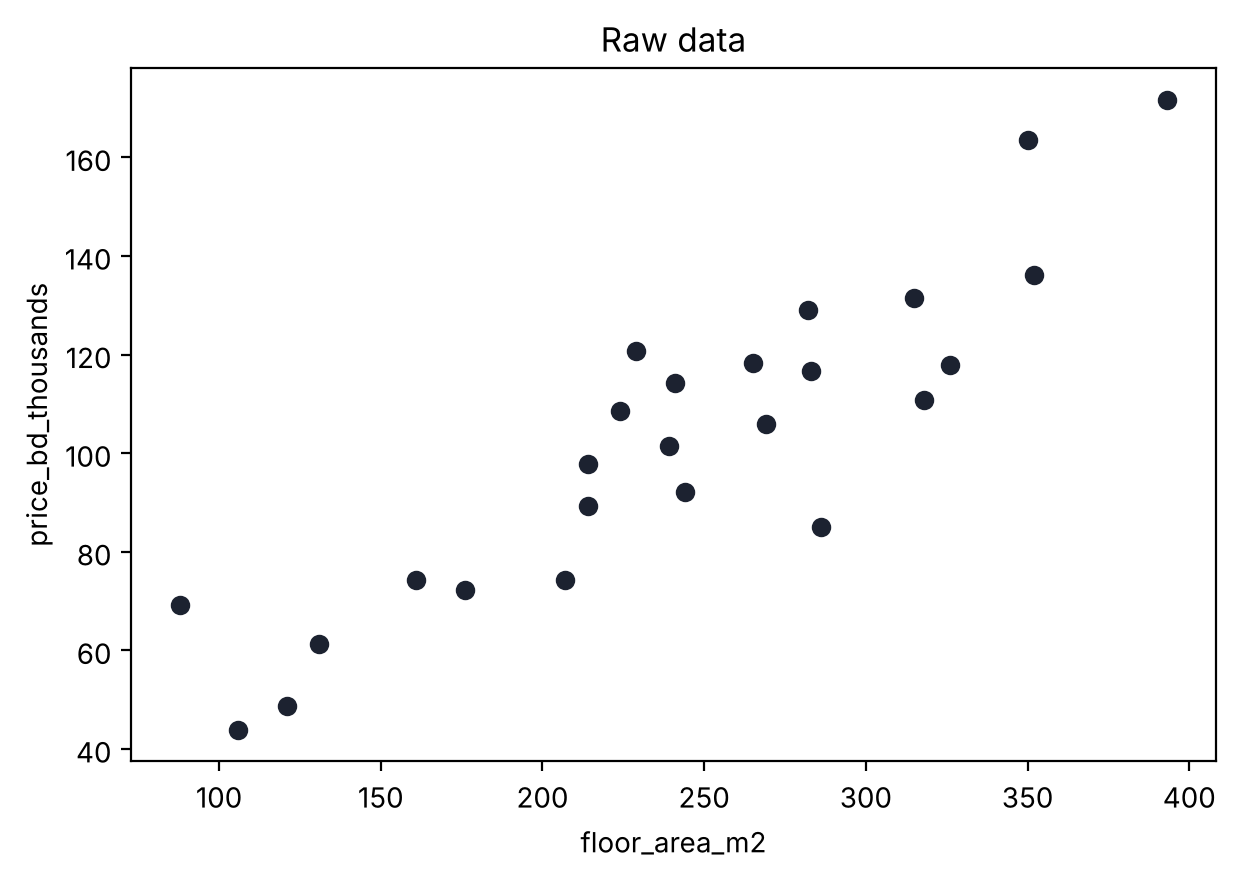

In [2]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(x, y, color="#1c2230")
ax.set(xlabel=x_name, ylabel=y_name, title="Raw data")
plt.show()

## 2. Fit the line with least squares

The model is $\hat y = m x + b$. Minimising the sum of squared errors gives the closed-form solution

$$m = \frac{\sum_i (x_i-\bar x)(y_i-\bar y)}{\sum_i (x_i-\bar x)^2}, \qquad b = \bar y - m\bar x$$

In [3]:
x_mean, y_mean = x.mean(), y.mean()
m = np.sum((x - x_mean) * (y - y_mean)) / np.sum((x - x_mean) ** 2)
b = y_mean - m * x_mean
y_hat = m * x + b
print(f"ŷ = {m:.4f}·x + {b:.4f}")

ŷ = 0.3600·x + 15.3014


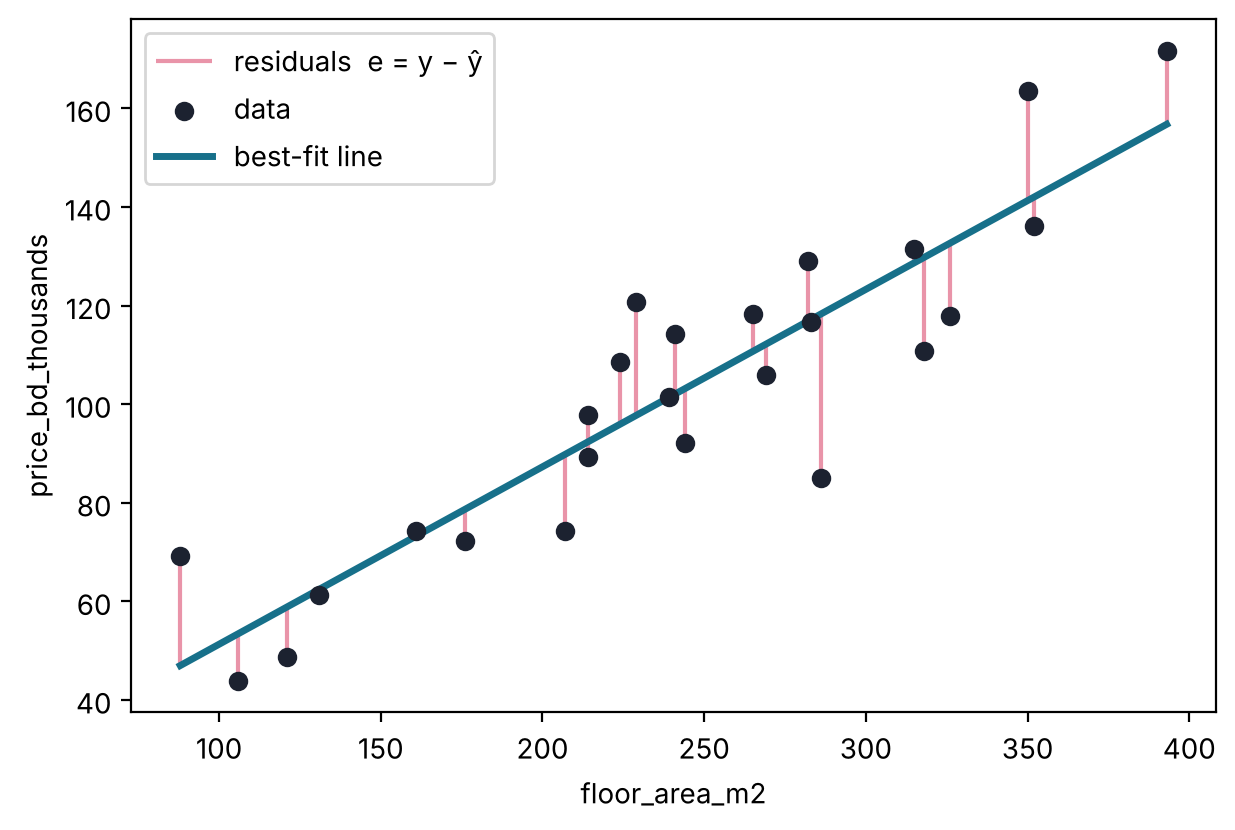

In [4]:
order = np.argsort(x)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.vlines(x, y, y_hat, color="#d52a55", alpha=0.5, label="residuals  e = y − ŷ")
ax.scatter(x, y, color="#1c2230", zorder=3, label="data")
ax.plot(x[order], y_hat[order], color="#17708a", lw=2.5, label="best-fit line")
ax.set(xlabel=x_name, ylabel=y_name); ax.legend()
plt.show()

## 3. Evaluation metrics from their definitions

| Metric | Formula | Units |
|---|---|---|
| MAE | $\frac1n\sum \lvert y_i-\hat y_i\rvert$ | same as y |
| MSE | $\frac1n\sum (y_i-\hat y_i)^2$ | y² |
| RMSE | $\sqrt{\text{MSE}}$ | same as y |
| R² | $1-\frac{\text{SSE}}{\text{SST}}$ | none |
| Adjusted R² | $1-(1-R^2)\frac{n-1}{n-p-1}$ | none |
| MAPE | $\frac{100\%}{n}\sum \left\lvert\frac{y_i-\hat y_i}{y_i}\right\rvert$ | % |

In [5]:
def regression_report(y, y_hat, p=1):
    e = y - y_hat
    n = len(y)
    sse, sst = np.sum(e ** 2), np.sum((y - y.mean()) ** 2)
    r2 = 1 - sse / sst
    nz = y != 0
    return {
        "MAE": np.mean(np.abs(e)),
        "MSE": np.mean(e ** 2),
        "RMSE": np.sqrt(np.mean(e ** 2)),
        "R²": r2,
        "Adjusted R²": 1 - (1 - r2) * (n - 1) / (n - p - 1),
        "MAPE %": np.mean(np.abs(e[nz] / y[nz])) * 100,
    }

ours = regression_report(y, y_hat)
pd.Series(ours, name="from scratch").round(4)

MAE             10.9208
MSE            186.7060
RMSE            13.6640
R²               0.8110
Adjusted R²      0.8028
MAPE %          11.5955
Name: from scratch, dtype: float64

## 4. Check against scikit-learn

In [6]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error

model = LinearRegression().fit(x.reshape(-1, 1), y)
pred = model.predict(x.reshape(-1, 1))
sk = {
    "MAE": mean_absolute_error(y, pred),
    "MSE": mean_squared_error(y, pred),
    "RMSE": np.sqrt(mean_squared_error(y, pred)),
    "R²": r2_score(y, pred),
    "Adjusted R²": np.nan,                       # not built in
    "MAPE %": mean_absolute_percentage_error(y, pred) * 100,
}
print(f"scikit-learn: m = {model.coef_[0]:.4f}, b = {model.intercept_:.4f}")
pd.DataFrame({"from scratch": ours, "scikit-learn": sk}).round(4)

scikit-learn: m = 0.3600, b = 15.3014


,from scratch,scikit-learn
MAE,10.9208,10.9208
MSE,186.7060,186.7060
RMSE,13.6640,13.6640
R²,0.8110,0.8110
Adjusted R²,0.8028,NaN
MAPE %,11.5955,11.5955


## 5. Outliers: MAE vs RMSE

We push one point further and further away and watch the metrics. MAE grows linearly; RMSE grows much faster because errors are squared before averaging.

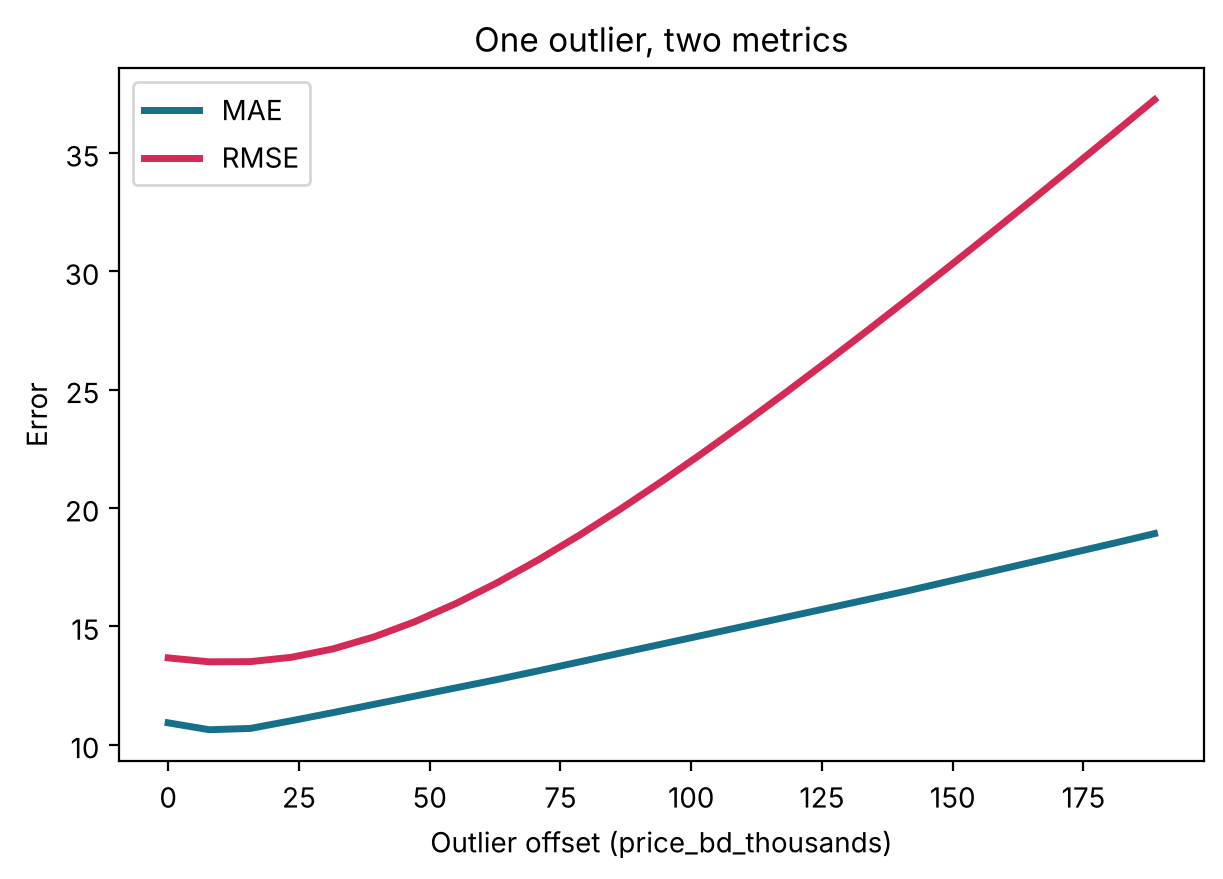

RMSE / MAE: 1.25 without the outlier → 1.97 with it


In [7]:
offsets = np.linspace(0, 6, 25) * y.std()
rows = []
for off in offsets:
    y_out = y.copy()
    y_out[0] += off
    mm, bb = np.polyfit(x, y_out, 1)
    r = regression_report(y_out, mm * x + bb)
    rows.append((off, r["MAE"], r["RMSE"]))
rows = np.array(rows)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(rows[:, 0], rows[:, 1], color="#17708a", lw=2.5, label="MAE")
ax.plot(rows[:, 0], rows[:, 2], color="#d52a55", lw=2.5, label="RMSE")
ax.set(xlabel=f"Outlier offset ({y_name})", ylabel="Error", title="One outlier, two metrics"); ax.legend()
plt.show()
print(f"RMSE / MAE: {rows[0, 2] / rows[0, 1]:.2f} without the outlier → {rows[-1, 2] / rows[-1, 1]:.2f} with it")

## 6. Evaluate on unseen data

Metrics on the training data are optimistic. Hold out a test set and report the metrics there.

In [8]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(x.reshape(-1, 1), y, test_size=0.25, random_state=42)
model = LinearRegression().fit(X_train, y_train)

report = pd.DataFrame({
    "train": regression_report(y_train, model.predict(X_train)),
    "test": regression_report(y_test, model.predict(X_test)),
}).round(4)
report

,train,test
MAE,10.9380,12.6705
MSE,185.6112,235.4096
RMSE,13.6239,15.3431
R²,0.7658,0.7303
Adjusted R²,0.7511,0.6764
MAPE %,13.0490,9.4250


## 7. Exercises

1. Change `DATASET` to `no_relationship_noise.csv`. What happens to R² and to the p-value of the slope? Why?
2. In section 5, which metric would you report to a client who cares about *typical* error? Which one if a single large miss is very costly?
3. Add a column of random noise as a second feature (`np.random.randn(len(x))`) and fit a `LinearRegression` on both columns. Compare R² and adjusted R² before and after.
4. Find a dataset where MAPE is misleading. *Hint: what if some true values are close to 0?*
5. Implement gradient descent for `m` and `b` and check that it converges to the OLS solution. Try different learning rates (see section 6 of the website).